## TX00DZ62-3011 tapaaminen 2. ja 4.11.2026

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd # install pandas package, and openpyxl + xlrd for excel-related utilities

## Pandas

Pandas is a package that is based on NumPy arrays but provides additional functionality on top of NumPy for one- and two-dimensional data. Pandas gives also access to the raw NumPy data. For a wide variety of tutorials on Pandas, see https://pandas.pydata.org/pandas-docs/stable/getting_started/tutorials.html. The one recommended to get started is https://pandas.pydata.org/pandas-docs/stable/getting_started/intro_tutorials/index.html. 

In Pandas, data is stored as a data frame, which contains in addition to the data itself metainformation, such as column headings. Next, we take a look at how to read in data with pandas.

See https://pandas.pydata.org/pandas-docs/stable/getting_started/overview.html for an overview of pandas package.

### Read in data

Pandas can read in data in a multitude of formats (see https://pandas.pydata.org/pandas-docs/stable/user_guide/io.html). Here a csv file is read. Files can be read from network with http in addition to local disk. Here a two-dimensional data is read into a DataFrame, which has multiple columns (pandas type Series).

#### Read from local disk

In [2]:
example = pd.read_csv("example.csv", sep=";")
print(example)

   year  credits  grade
0  2018        5      5
1  2018        3      4
2  2018        2      1
3  2019        5      4
4  2019        5      3
5  2019        5      5
6  2020        3      4
7  2020        5      4


#### Read from network with HTTP

In [3]:
example_n = pd.read_csv("https://users.metropolia.fi/~peterh/example.csv", sep=";")
print(example_n)

    year  credits  grade
0   2018        5    5.0
1   2018        3    4.0
2   2018        2    3.0
3   2018        5    4.0
4   2019        5    NaN
5   2019        5    3.0
6   2019        5    5.0
7   2020        3    4.0
8   2020        5    4.0
9   2021        5    NaN
10  2021        5    3.0
11  2021        5    5.0
12  2021       15    3.0


## JSON ja Pandas

JSON-muotoinen tieto voidaan lukea usein suoraan Pandas dataframeksi. Sama metodi (read_json()) toimii sekä verkko-osoitteille että tiedostoille.

In [4]:
import pandas as pd

eduskuntadf = pd.read_json("https://users.metropolia.fi/~peterh/mps.json")
print(eduskuntadf)

     personNumber  seatNumber           last     first party  minister  \
0            1467          64           Huru     Petri    ps     False   
1            1415         168         Kemppi    Hilkka  kesk     False   
2            1394         197  Keto-Huovinen     Pihla   kok     False   
3             464          20       Kiljunen     Kimmo    sd     False   
4             791          21       Kiljunen    Anneli    sd     False   
..            ...         ...            ...       ...   ...       ...   
195          1136          35       Vähämäki     Ville    ps     False   
196           794          73      Väätäinen     Tuula    sd     False   
197          1407         156       Yrttiaho  Johannes   vas     False   
198           301          56      Zyskowicz       Ben   kok     False   
199          1141          84         Östman     Peter    kd     False   

                                               picture  \
0    attachment/member/pictures/Huru-Petri-web-v000..

Pandas dataframe voidaan kirjoittaa Python-hakemistoksi. Python-hakemiston perusteella voidaan myös luoda Pandas dataframe, josta puolestaan voidaan tuottaa JSON-muotoinen esitys:

In [5]:
# tässä luodaan vaalipiirit -hakemisto esimerkkiä varten
eduskunta = eduskuntadf.to_dict(orient='records') 
print(eduskunta[:3])

vaalipiirit = {}

for ed in eduskunta:
    if ed['constituency'] in vaalipiirit:
        vaalipiirit[ed['constituency']] += 1
    else:
        vaalipiirit[ed['constituency']] = 1

vpdf = pd.DataFrame(vaalipiirit.items())
print(vpdf)
vpdfjson = pd.DataFrame.to_json(vpdf, orient='values')
print(vpdfjson)

[{'personNumber': 1467, 'seatNumber': 64, 'last': 'Huru', 'first': 'Petri', 'party': 'ps', 'minister': False, 'picture': 'attachment/member/pictures/Huru-Petri-web-v0003-1467.jpg', 'twitter': 'https://twitter.com/HuruPetri', 'bornYear': 1966, 'constituency': 'Satakunta'}, {'personNumber': 1415, 'seatNumber': 168, 'last': 'Kemppi', 'first': 'Hilkka', 'party': 'kesk', 'minister': False, 'picture': 'attachment/member/pictures/Kemppi-Hilkka-web-v6614-1415.JPG', 'twitter': '', 'bornYear': 1988, 'constituency': 'Häme'}, {'personNumber': 1394, 'seatNumber': 197, 'last': 'Keto-Huovinen', 'first': 'Pihla', 'party': 'kok', 'minister': False, 'picture': 'attachment/member/pictures/Keto-Huovinen-Pihla-web-V7487-1394.jpg', 'twitter': '', 'bornYear': 1974, 'constituency': 'Uusimaa'}]
                  0   1
0         Satakunta   8
1              Häme  14
2           Uusimaa  36
3    Kaakkois-Suomi  17
4      Savo-Karjala  15
5              Oulu  18
6         Pirkanmaa  19
7          Helsinki  22
8  

## SQL ja Pandas

Tiedon lukeminen SQL-tietokannasta Pandas dataframeksi on suoraviivaista:

In [6]:
import sqlite3

conn = sqlite3.connect('mps.db')

sqleduskuntadf = pd.read_sql_query("SELECT * FROM eduskunta", conn)
print(sqleduskuntadf.columns)
print(len(sqleduskuntadf))

Index(['personnumber', 'last', 'first', 'party', 'constituency', 'bornyear'],
      dtype='str')
200


Pandas dataframe voidaan myös kirjoittaa SQL-tietokannan tauluksi:

In [7]:
conn = sqlite3.connect('mps.db')
eduskuntadf.to_sql(name = 'edustajat', con = conn, if_exists = 'replace') # mikäli taulu oli jo olemassa, korvataan se

cursor = conn.cursor()
cursor.execute('''
    select * from edustajat
''')
print(cursor.fetchall()[:3])

[(0, 1467, 64, 'Huru', 'Petri', 'ps', 0, 'attachment/member/pictures/Huru-Petri-web-v0003-1467.jpg', 'https://twitter.com/HuruPetri', 1966, 'Satakunta'), (1, 1415, 168, 'Kemppi', 'Hilkka', 'kesk', 0, 'attachment/member/pictures/Kemppi-Hilkka-web-v6614-1415.JPG', '', 1988, 'Häme'), (2, 1394, 197, 'Keto-Huovinen', 'Pihla', 'kok', 0, 'attachment/member/pictures/Keto-Huovinen-Pihla-web-V7487-1394.jpg', '', 1974, 'Uusimaa')]


### Accessing data

Note that the data set has row numbers added. To access the data, columns (Series) can be selected by column name. By default all rows are selected, but a subset can be defined. For more complicated expressions .loc must be used, as is seen in the combination of row and column selection example. This gives much of the NumPy where() functionality.

In [8]:
print(example.index)
print(example.columns)
print(example[["year","grade"]])
print(example[example["credits"] == 5])
print(example.loc[example["credits"] == 5,["year","grade"]])

RangeIndex(start=0, stop=8, step=1)
Index(['year', 'credits', 'grade'], dtype='str')
   year  grade
0  2018      5
1  2018      4
2  2018      1
3  2019      4
4  2019      3
5  2019      5
6  2020      4
7  2020      4
   year  credits  grade
0  2018        5      5
3  2019        5      4
4  2019        5      3
5  2019        5      5
7  2020        5      4
   year  grade
0  2018      5
3  2019      4
4  2019      3
5  2019      5
7  2020      4


#### Pandas and NumPy

Pandas data frame can be converted into NumPy array, if further processing with Pandas is not necessary. Also reverse process is possible; a NumPy (two-dimensional) array can be converted into Pandas dataframe.

In [9]:
example_p = example.to_numpy()
print(example_p.shape)
print(example_p)

(8, 3)
[[2018    5    5]
 [2018    3    4]
 [2018    2    1]
 [2019    5    4]
 [2019    5    3]
 [2019    5    5]
 [2020    3    4]
 [2020    5    4]]


In [10]:
mydata = np.array([[170,166,171,181,188],[63,71,77,78,81]])
mydata_pd = pd.DataFrame({'Height': mydata[0,:], 'Weight': mydata[1,:]})
print(mydata_pd)

   Height  Weight
0     170      63
1     166      71
2     171      77
3     181      78
4     188      81


#### Write data

A data frame can be written to file in multiple formats. Here Excel format is used.

In [11]:
example.to_excel("example.xlsx", index=False)

#### Summary statistics

Summary statistics for columns (and rows, too, if needed) are available. Summaries can be computed for selections, too.

In [12]:
print(example["grade"].mean())
print(example["credits"].sum())
print(example.loc[example["year"] == 2019, "grade"].mean())
print(example["year"].value_counts())

3.75
33
4.0
year
2018    3
2019    3
2020    2
Name: count, dtype: int64


Summary statistics can be based on grouping.

In [13]:
example[["year", "credits"]].groupby("year").sum()

,credits
year,
2018,10
2019,15
2020,8


An easy way to get some summary statistics from the data.

In [14]:
print(example.describe()) # or, less confusingly:
print(example[['credits', 'grade']].describe())

              year   credits    grade
count     8.000000  8.000000  8.00000
mean   2018.875000  4.125000  3.75000
std       0.834523  1.246423  1.28174
min    2018.000000  2.000000  1.00000
25%    2018.000000  3.000000  3.75000
50%    2019.000000  5.000000  4.00000
75%    2019.250000  5.000000  4.25000
max    2020.000000  5.000000  5.00000
        credits    grade
count  8.000000  8.00000
mean   4.125000  3.75000
std    1.246423  1.28174
min    2.000000  1.00000
25%    3.000000  3.75000
50%    5.000000  4.00000
75%    5.000000  4.25000
max    5.000000  5.00000


#### Plotting

Pandas data frames can be plotted to get a visual impression of the data. Plotting in Pandas uses matplotlib, and matplotlib settings for colors etc. are available.

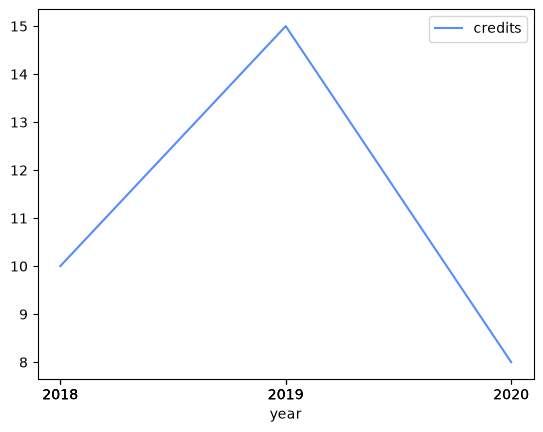

In [15]:
# ; at the end of the line suppresses messages from plot()
myp1 = example[["year", "credits"]].groupby("year").sum().plot()
myp1.set_xticks(example["year"]);

#### Combine data

Multiple frames can be combined in both vertical (axis=0) and horizontal (axis=1) directions. A data frame can be sorted by one or more criteria.

In [16]:
example2 = pd.read_csv("example2.csv")
print(example2)
example_all = pd.concat([example,example2],axis=0,ignore_index=True)
print(example_all)
print(example_all[["year", "credits"]].groupby("year").sum())
coursenames = pd.read_csv("coursenames.csv")
print(coursenames)
example_names = pd.concat([example,coursenames],axis=1)
print(example_names)
example_sorted = example_all.sort_values(by="year")
print(example_sorted)

   year  credits  grade
0  2016        5      2
1  2016        3      5
2  2016       15      1
3  2017        5      5
4  2016        5      2
5  2017        3      4
6  2017        3      5
7  2017       15      2
8  2017        1      5
9  2016        2      5
    year  credits  grade
0   2018        5      5
1   2018        3      4
2   2018        2      1
3   2019        5      4
4   2019        5      3
5   2019        5      5
6   2020        3      4
7   2020        5      4
8   2016        5      2
9   2016        3      5
10  2016       15      1
11  2017        5      5
12  2016        5      2
13  2017        3      4
14  2017        3      5
15  2017       15      2
16  2017        1      5
17  2016        2      5
      credits
year         
2016       30
2017       27
2018       10
2019       15
2020        8
               name
0         Physics 1
1         Physics 2
2     Mathematics 1
3     Mathematics 2
4     Programming 1
5     Programming 2
6     Programming 3
7  

In [17]:
# correlation between data series

print(example_sorted['grade'].corr(example_sorted['credits']))

-0.5437950311197375


#### Long vs wide tables and pivoting

Pivoting is available to do conversion from long to wide format and vice versa. Pivoting is often done in combination with aggregation (such as summing up values, computing mean, max, min etc), but can be done without.

In [18]:
example3 = pd.read_excel("example3.xlsx")
print(example3)
print(example3.pivot(columns=["Year"]))

   Student  Credits  Year
0    Mikko        5  2020
1    Maija        3  2019
2   Matias        3  2018
3    Elina        5  2019
4     Kira        3  2020
5    Mikko        5  2018
6    Maija        3  2018
7   Matias        3  2019
8    Elina        3  2020
9     Kira        3  2020
10   Mikko        5  2018
11   Maija        3  2018
12  Matias        3  2019
13   Elina        5  2020
14    Kira        5  2019
15   Mikko       15  2019
16   Elina       10  2018
     Student                Credits           
Year    2018    2019   2020    2018  2019 2020
0        NaN     NaN  Mikko     NaN   NaN  5.0
1        NaN   Maija    NaN     NaN   3.0  NaN
2     Matias     NaN    NaN     3.0   NaN  NaN
3        NaN   Elina    NaN     NaN   5.0  NaN
4        NaN     NaN   Kira     NaN   NaN  3.0
5      Mikko     NaN    NaN     5.0   NaN  NaN
6      Maija     NaN    NaN     3.0   NaN  NaN
7        NaN  Matias    NaN     NaN   3.0  NaN
8        NaN     NaN  Elina     NaN   NaN  3.0
9        NaN   

Pivoted values can be aggregated in two ways:

In [19]:
print(example3.pivot_table(values="Credits", index="Student", columns="Year", aggfunc="sum"))
print(example3.pivot_table(values="Credits", index="Year", columns="Student", aggfunc="sum"))

Year     2018  2019  2020
Student                  
Elina    10.0   5.0   8.0
Kira      NaN   5.0   6.0
Maija     6.0   3.0   NaN
Matias    3.0   6.0   NaN
Mikko    10.0  15.0   5.0
Student  Elina  Kira  Maija  Matias  Mikko
Year                                      
2018      10.0   NaN    6.0     3.0   10.0
2019       5.0   5.0    3.0     6.0   15.0
2020       8.0   6.0    NaN     NaN    5.0


#### Dealing with missing / corrupted data

Pandas has several functions that can be used to deal with missing data. Usually, if a data item is missing, its value appears in Pandas dataframe as NaN. NaNs can be removed with dropna(), replaced by other values with fillna() and interpolated with interpolate().

Sometimes it makes sense to omit data (rows in the beginning and end of file) when reading in a data file, see for example https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_excel.html for more.

In [20]:
example4 = pd.read_excel("example4.xlsx")
print(example4)

      A    B      C
0  23.0  100    NaN
1  34.0  100  201.0
2  34.0  fff  202.0
3  45.0  101    NaN
4   NaN  102  204.0


In [22]:
example4 = example4.apply(pd.to_numeric, errors='coerce')
print(example4)
print(example4.dropna())
print(example4.fillna(0))
print(example4.ffill())
example4_clean = example4.ffill().bfill()
print(example4_clean)

      A      B      C
0  23.0  100.0    NaN
1  34.0  100.0  201.0
2  34.0    NaN  202.0
3  45.0  101.0    NaN
4   NaN  102.0  204.0
      A      B      C
1  34.0  100.0  201.0
      A      B      C
0  23.0  100.0    0.0
1  34.0  100.0  201.0
2  34.0    0.0  202.0
3  45.0  101.0    0.0
4   0.0  102.0  204.0
      A      B      C
0  23.0  100.0    NaN
1  34.0  100.0  201.0
2  34.0  100.0  202.0
3  45.0  101.0  202.0
4  45.0  102.0  204.0
      A      B      C
0  23.0  100.0  201.0
1  34.0  100.0  201.0
2  34.0  100.0  202.0
3  45.0  101.0  202.0
4  45.0  102.0  204.0
